# 02 - Preprocessing and data pipeline
Notebook 01 already **cleaned the data and split it by patient** (verified on disk), so nothing is re-split here. This notebook:

1. **Verifies the split** against `manifest.csv` and the files on disk (no patient or duplicate crosses train/val/test).
2. *(optional)* creates **patient-level 5-fold cross-validation folds** over train+val (`folds.csv`), for a stronger paper protocol. The test set stays untouched.
3. Builds the **preprocessing**: normalisation and OCT-safe augmentation (train) vs a deterministic transform (val/test), and shows what they do.
4. Builds the **datasets, class-balanced sampler and DataLoaders**.
5. **Sanity-checks** the pipeline: shapes, value ranges, NaN/Inf, label balance.
6. **Benchmarks** loading speed (picks `NUM_WORKERS`) and runs a short **GPU smoke test** of the full pipeline.
7. Saves `pipeline.json` (all settings) next to the dataset.

Needs PyTorch + torchvision. Takes a few minutes.

## 1. Settings

In [1]:
import os, csv, json, time, random, collections
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision
from torch.utils.data import DataLoader, WeightedRandomSampler, RandomSampler
from torchvision import datasets, transforms

# ---------------- settings ----------------
OUT_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT_clean")    # dataset written by notebook 01

IMG_SIZE = 224                   # network input (the dataset is stored at 256)
NORM = "imagenet"                # "imagenet": for ImageNet-pretrained backbones | "dataset": mean/std of the clean data
BATCH_SIZE = 32
NUM_WORKERS = 0 if os.name == "nt" else 4     # the speed test in section 6 tells you if more is worth it
SAMPLER = "balanced"             # "balanced": class-balanced draws | "natural": draws follow the real class mix
SAMPLES_PER_EPOCH = 30000        # images drawn per training epoch
SEED = 42
MAKE_FOLDS, N_FOLDS = True, 5    # optional patient-level cross-validation folds

AUG = dict(                      # training augmentation, chosen to keep OCT anatomy plausible
    crop_scale=(0.75, 1.0), crop_ratio=(0.9, 1.1),     # random zoom/crop (retina stays recognisable)
    flip_p=0.5,                                        # horizontal flip only (up/down order of retinal layers matters)
    rotate_deg=10, rotate_p=0.5,                       # small tilt, as in real acquisition
    brightness=0.2, contrast=0.2,                      # scanner gain differences
    blur_p=0.2,                                        # slight softening
    erase_p=0.25,                                      # small random patches, makes the network use several cues
)
# -------------------------------------------

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if not (OUT_ROOT / "train").is_dir() or not (OUT_ROOT / "manifest.csv").exists():
    raise FileNotFoundError(f"No clean dataset at {OUT_ROOT}. Run notebook 01 first (or fix OUT_ROOT).")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Verify the split
The split was made in notebook 01 by patient group (patients and duplicate images linked), stratified by class.
Here we only **check** it: manifest vs files on disk, and that nothing crosses a split boundary.

In [2]:
with open(OUT_ROOT / "manifest.csv", newline="", encoding="utf-8") as f:
    M = list(csv.DictReader(f))
SPLITS = ("train", "val", "test")
CLASSES = sorted({r["cls"] for r in M})
K = len(CLASSES)

print("  " + "split".ljust(6) + "".join(c.rjust(9) for c in CLASSES) + "    total   patients   groups")
for s in SPLITS:
    rows = [r for r in M if r["split"] == s]
    cnt = [sum(1 for r in rows if r["cls"] == c) for c in CLASSES]
    print("  " + s.ljust(6) + "".join(f"{n:9,d}" for n in cnt) +
          f"{len(rows):9,d}{len({r['patient'] for r in rows}):10,d}{len({r['group'] for r in rows}):9,d}")

def check(name, ok, detail=""):
    print(("PASS  " if ok else "FAIL  ") + name + (f"  ({detail})" if detail else ""))
    return bool(ok)

ok = []
g_splits, p_splits = collections.defaultdict(set), collections.defaultdict(set)
for r in M:
    g_splits[r["group"]].add(r["split"])
    if r["patient"]:
        p_splits[r["patient"]].add(r["split"])
ok.append(check("no patient group in two splits", all(len(v) == 1 for v in g_splits.values())))
ok.append(check("no patient ID in two splits", all(len(v) == 1 for v in p_splits.values())))
ok.append(check("no byte-identical images", len({r["md5"] for r in M}) == len(M)))
on_disk = {s: sum(1 for p in (OUT_ROOT / s).rglob("*") if p.suffix.lower() in (".png", ".jpg", ".jpeg")) for s in SPLITS}
in_manifest = {s: sum(1 for r in M if r["split"] == s) for s in SPLITS}
ok.append(check("files on disk match the manifest", on_disk == in_manifest, f"{on_disk} vs {in_manifest}"))
print("\n" + ("Split verified - nothing to redo." if all(ok) else "PROBLEM: re-run notebook 01 (FORCE = True)."))

STATS_FILE = OUT_ROOT / "stats.json"
STATS = json.load(open(STATS_FILE)) if STATS_FILE.exists() else None
if STATS:
    print(f"Dataset stats: pixel mean {STATS['mean']:.4f}, std {STATS['std']:.4f} | stored size {STATS['image_size']}px "
          f"| split mode {STATS['split_mode']} | resize mode {STATS['resize_mode']}")

  split       CNV      DME   DRUSEN   NORMAL    total   patients   groups
  train    25,037    8,845    6,179   21,093   61,154     3,714    3,714
  val       3,136    1,081      878    2,694    7,789       502      502
  test      3,267    1,191      776    2,500    7,734       440      440
PASS  no patient group in two splits
PASS  no patient ID in two splits
PASS  no byte-identical images
PASS  files on disk match the manifest  ({'train': 61154, 'val': 7789, 'test': 7734} vs {'train': 61154, 'val': 7789, 'test': 7734})

Split verified - nothing to redo.
Dataset stats: pixel mean 0.1930, std 0.2219 | stored size 256px | split mode new_split | resize mode squash


## 3. Optional: patient-level cross-validation folds
Train and val are pooled and cut into `N_FOLDS` folds by patient group (stratified by class); **test is never touched**.
Use them later to report mean +/- std over folds instead of one lucky split. Written to `folds.csv`.

In [3]:
def split_groups(groups, fracs, names, seed):
    # groups: gid -> (class, n_images). Each group goes to the split furthest below its target share.
    rng = random.Random(seed)
    out = {}
    for cls in sorted({c for c, _ in groups.values()}):
        gids = sorted(g for g, (c, _) in groups.items() if c == cls)
        rng.shuffle(gids)
        total = sum(groups[g][1] for g in gids)
        target = {n: f * total for n, f in zip(names, fracs)}
        cur = {n: 0 for n in names}
        for g in gids:
            best = max(names, key=lambda n: (target[n] - cur[n]) / max(target[n], 1e-9))
            out[g] = best
            cur[best] += groups[g][1]
    return out

if MAKE_FOLDS:
    pool = [r for r in M if r["split"] in ("train", "val")]
    members = collections.defaultdict(list)
    for r in pool:
        members[r["group"]].append(r)
    table = {g: (collections.Counter(x["cls"] for x in m).most_common(1)[0][0], len(m)) for g, m in members.items()}
    fold_of = split_groups(table, tuple([1.0 / N_FOLDS] * N_FOLDS), tuple(range(N_FOLDS)), SEED)
    with open(OUT_ROOT / "folds.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["path", "fold"])
        for r in pool:
            w.writerow([r["path"], fold_of[r["group"]]])
    print("  " + "fold".ljust(6) + "".join(c.rjust(9) for c in CLASSES) + "    total")
    for k in range(N_FOLDS):
        rows = [r for r in pool if fold_of[r["group"]] == k]
        print("  " + str(k).ljust(6) + "".join(f"{sum(1 for r in rows if r['cls'] == c):9,d}" for c in CLASSES) + f"{len(rows):9,d}")
    p_fold = collections.defaultdict(set)
    for r in pool:
        p_fold[r["patient"]].add(fold_of[r["group"]])
    sizes = [sum(1 for r in pool if fold_of[r["group"]] == k) for k in range(N_FOLDS)]
    check("no patient appears in two folds", all(len(v) == 1 for v in p_fold.values()))
    check("folds are similar in size", max(sizes) <= 1.25 * min(sizes), f"{min(sizes)}..{max(sizes)} images")
    print("Saved", OUT_ROOT / "folds.csv")
else:
    print("MAKE_FOLDS = False - skipped.")

  fold        CNV      DME   DRUSEN   NORMAL    total
  0         5,594    1,957    1,498    4,746   13,795
  1         5,566    2,021    1,330    4,871   13,788
  2         5,625    2,007    1,386    4,770   13,788
  3         5,887    1,903    1,341    4,740   13,871
  4         5,501    2,038    1,502    4,660   13,701
PASS  no patient appears in two folds
PASS  folds are similar in size  (13701..13871 images)
Saved C:\Users\User\Desktop\retinaldataset\OCT_clean\folds.csv


## 4. Preprocessing
- **Validation / test**: resize to the network size, tensor, normalise. Deterministic.
- **Training**: random crop/zoom, horizontal flip, small rotation, brightness/contrast, light blur, tiny random patches, then the same normalisation.
- **Normalisation**: ImageNet statistics for pretrained backbones (default); switch `NORM = "dataset"` to use the clean data's own mean/std.
- Speckle noise is kept on purpose (it is part of the signal); no vertical flips (retinal layers have a fixed order).

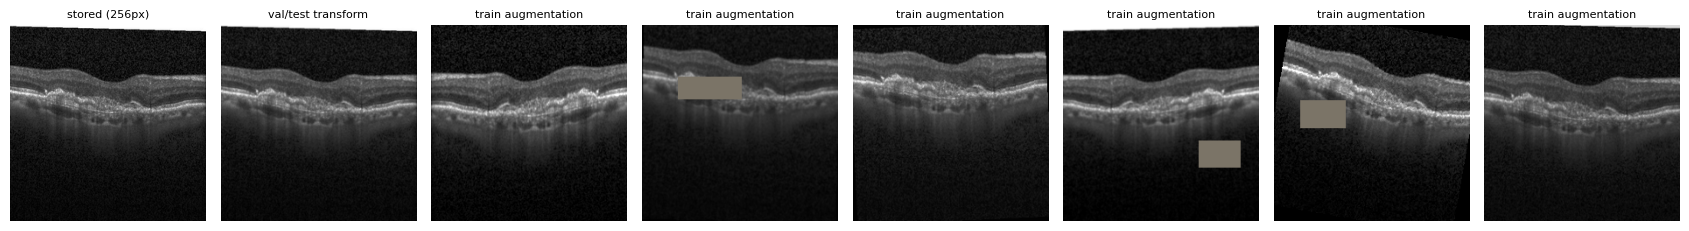

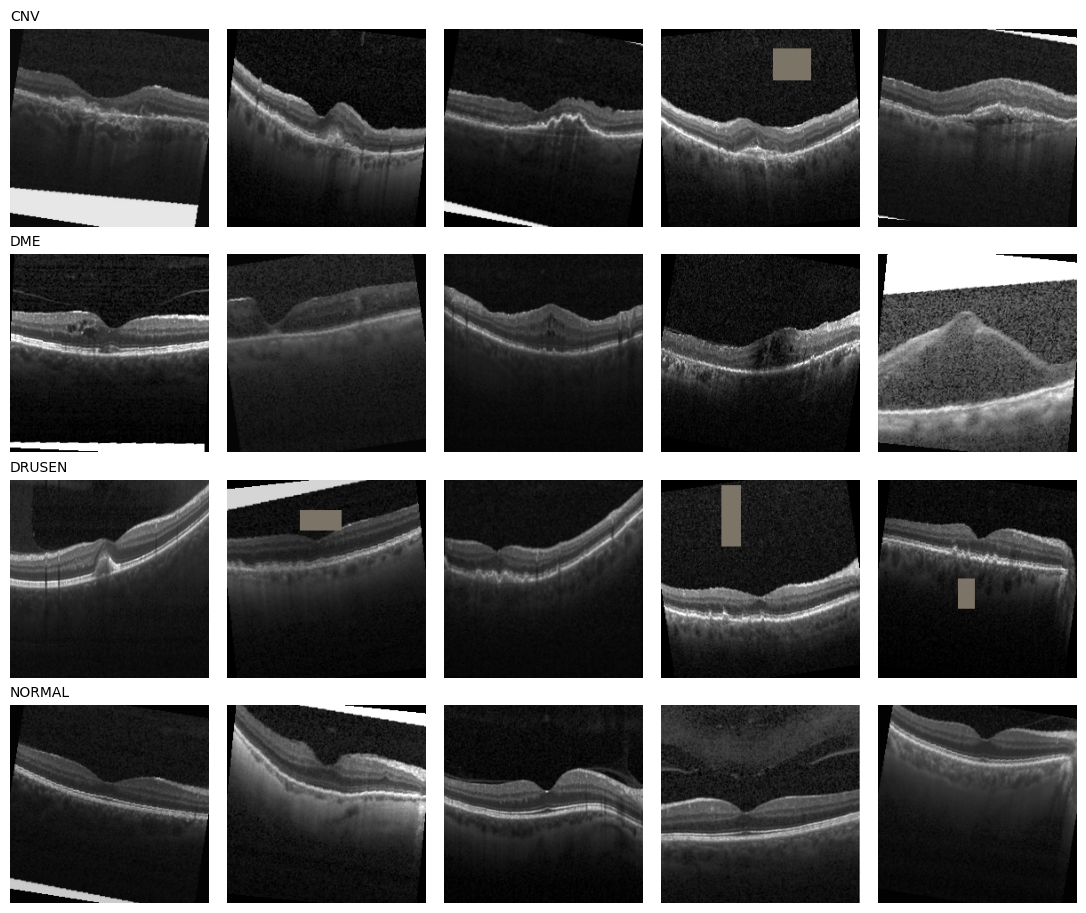

In [4]:
if NORM == "imagenet":
    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
else:
    assert STATS is not None, "stats.json missing - run notebook 01 or use NORM = 'imagenet'"
    MEAN, STD = [STATS["mean"]] * 3, [STATS["std"]] * 3

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=AUG["crop_scale"], ratio=AUG["crop_ratio"]),
    transforms.RandomHorizontalFlip(AUG["flip_p"]),
    transforms.RandomApply([transforms.RandomRotation(AUG["rotate_deg"], fill=0)], p=AUG["rotate_p"]),
    transforms.ColorJitter(brightness=AUG["brightness"], contrast=AUG["contrast"]),
    transforms.RandomApply([transforms.GaussianBlur(3, sigma=(0.1, 1.0))], p=AUG["blur_p"]),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=AUG["erase_p"], scale=(0.01, 0.04), ratio=(0.3, 3.3), value=0),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
to_img = lambda t: (t * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

# one scan: stored version, evaluation version, and 6 random training augmentations
sample = [r for r in M if r["split"] == "train" and r["cls"] == CLASSES[0]][0]
img = Image.open(OUT_ROOT / sample["path"]).convert("RGB")
fig, axs = plt.subplots(1, 8, figsize=(17, 2.6))
axs[0].imshow(img); axs[0].set_title(f"stored ({img.size[0]}px)", fontsize=8)
axs[1].imshow(to_img(eval_tf(img))); axs[1].set_title("val/test transform", fontsize=8)
for ax in axs[2:]:
    ax.imshow(to_img(train_tf(img))); ax.set_title("train augmentation", fontsize=8)
for ax in axs:
    ax.axis("off")
plt.tight_layout(); plt.show()

# one augmented example per class, several scans
fig, axs = plt.subplots(K, 5, figsize=(11, 2.3 * K), squeeze=False)
rng = np.random.default_rng(0)
for r_i, c in enumerate(CLASSES):
    pool = [r for r in M if r["split"] == "train" and r["cls"] == c]
    for c_i, k in enumerate(rng.choice(len(pool), size=5, replace=False)):
        axs[r_i, c_i].imshow(to_img(train_tf(Image.open(OUT_ROOT / pool[k]["path"]).convert("RGB"))))
        axs[r_i, c_i].axis("off")
        if c_i == 0:
            axs[r_i, c_i].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Datasets, sampler and loaders
`ImageFolder` reads the clean folders. Training draws `SAMPLES_PER_EPOCH` images per epoch; with `SAMPLER = "balanced"` every class is drawn equally often
(NORMAL would otherwise dominate). Class weights are also saved in case you prefer weighting the loss.

In [5]:
ds_train = datasets.ImageFolder(OUT_ROOT / "train", train_tf)
ds_val = datasets.ImageFolder(OUT_ROOT / "val", eval_tf)
ds_test = datasets.ImageFolder(OUT_ROOT / "test", eval_tf)
assert ds_train.classes == ds_val.classes == ds_test.classes == CLASSES, "class folders differ between splits"
for name, ds in (("train", ds_train), ("val", ds_val), ("test", ds_test)):
    assert len(ds) == in_manifest[name], f"{name}: {len(ds)} files vs {in_manifest[name]} in manifest"

targets = np.array(ds_train.targets)
counts = np.bincount(targets, minlength=K)
CLASS_WEIGHTS = len(targets) / (K * counts)
sample_w = torch.as_tensor(1.0 / counts[targets], dtype=torch.double)

gen = torch.Generator()
gen.manual_seed(SEED)
if SAMPLER == "balanced":
    sampler = WeightedRandomSampler(sample_w, num_samples=SAMPLES_PER_EPOCH, replacement=True, generator=gen)
else:
    sampler = RandomSampler(ds_train, replacement=False, num_samples=min(SAMPLES_PER_EPOCH, len(ds_train)), generator=gen)

kw = dict(num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(ds_train, BATCH_SIZE, sampler=sampler, drop_last=True, generator=gen, **kw)
val_loader = DataLoader(ds_val, BATCH_SIZE * 2, shuffle=False, **kw)
test_loader = DataLoader(ds_test, BATCH_SIZE * 2, shuffle=False, **kw)

print(f"train {len(ds_train):,} | val {len(ds_val):,} | test {len(ds_test):,} | classes {CLASSES}")
draw = np.array(list(WeightedRandomSampler(sample_w, 20000, replacement=True, generator=torch.Generator().manual_seed(0))))
print("\nClass share per training epoch (20,000 draws):")
print("  " + "".join(c.rjust(9) for c in CLASSES))
print("  natural " + "".join(f"{n / len(targets) * 100:8.1f}%" for n in counts))
print("  balanced" + "".join(f"{(targets[draw] == k).mean() * 100:8.1f}%" for k in range(K)))
print("  class weights (for a weighted loss):", {c: round(float(w), 2) for c, w in zip(CLASSES, CLASS_WEIGHTS)})
print(f"\nSampler in use: {SAMPLER} | {len(train_loader)} steps per epoch of {BATCH_SIZE}")

train 61,154 | val 7,789 | test 7,734 | classes ['CNV', 'DME', 'DRUSEN', 'NORMAL']

Class share per training epoch (20,000 draws):
        CNV      DME   DRUSEN   NORMAL
  natural     40.9%    14.5%    10.1%    34.5%
  balanced    24.7%    24.7%    25.4%    25.2%
  class weights (for a weighted loss): {'CNV': 0.61, 'DME': 1.73, 'DRUSEN': 2.47, 'NORMAL': 0.72}

Sampler in use: balanced | 937 steps per epoch of 32


## 6. Sanity checks
Pulls batches from every loader and checks: shape and dtype, value range, **no NaN/Inf**, labels in range, and that training batches are class-balanced.
`FULL_SCAN = True` additionally reads every val and test image once (a few minutes).

In [6]:
FULL_SCAN = False

def check_loader(name, loader, n_batches=20):
    bad = n = 0
    lo, hi, shape = float("inf"), float("-inf"), None
    labels = collections.Counter()
    for b, (x, y) in enumerate(loader):
        if b >= n_batches:
            break
        shape = tuple(x.shape)
        bad += int(not torch.isfinite(x).all())
        lo, hi = min(lo, x.min().item()), max(hi, x.max().item())
        labels.update(y.tolist())
        n += len(y)
        assert x.dtype == torch.float32 and int(y.min()) >= 0 and int(y.max()) < K
    mix = "  ".join(f"{CLASSES[k]} {labels[k] / n * 100:3.0f}%" for k in range(K))
    check(f"{name:5s} batch {shape} | values {lo:+.2f}..{hi:+.2f} | NaN/Inf batches: {bad} | {mix}", bad == 0)
    return bad == 0

res = [check_loader("train", train_loader), check_loader("val", val_loader), check_loader("test", test_loader)]

if FULL_SCAN:
    for name, loader in (("val", val_loader), ("test", test_loader)):
        bad = sum(int(not torch.isfinite(x).all()) for x, _ in loader)
        res.append(check(f"full scan of {name}: {bad} batches with NaN/Inf", bad == 0))
print("\n" + ("Pipeline looks healthy." if all(res) else "PROBLEM - inspect the failed lines above."))

PASS  train batch (32, 3, 224, 224) | values -2.12..+2.64 | NaN/Inf batches: 0 | CNV  26%  DME  24%  DRUSEN  27%  NORMAL  23%
PASS  val   batch (64, 3, 224, 224) | values -2.12..+2.64 | NaN/Inf batches: 0 | CNV 100%  DME   0%  DRUSEN   0%  NORMAL   0%
PASS  test  batch (64, 3, 224, 224) | values -2.12..+2.64 | NaN/Inf batches: 0 | CNV 100%  DME   0%  DRUSEN   0%  NORMAL   0%

Pipeline looks healthy.


## 7. Speed: loading and a short GPU smoke test
Loading must keep up with the GPU. First the loader alone with 0, 2 and 4 workers, then 15 real training steps (forward + backward, mixed precision) with an untrained ConvNeXt-Tiny
to see how much time is spent waiting for data.

In [7]:
def bench(workers, n_batches=12):
    dl = DataLoader(ds_train, BATCH_SIZE, shuffle=True, num_workers=workers, pin_memory=DEVICE.type == "cuda")
    it = iter(dl)
    next(it)                                   # worker start-up is not counted
    t0, n = time.perf_counter(), 0
    for _ in range(n_batches):
        x, _ = next(it)
        n += len(x)
    return n / (time.perf_counter() - t0)

speeds = {}
for w in (0, 2, 4):
    try:
        speeds[w] = bench(w)
        print(f"  num_workers={w}: {speeds[w]:7.0f} images/s")
    except Exception as e:
        print(f"  num_workers={w}: failed ({type(e).__name__}: {str(e)[:80]})")
if speeds:
    best = max(speeds, key=speeds.get)
    print(f"\nFastest: num_workers={best}. You are using NUM_WORKERS={NUM_WORKERS}"
          + ("  -> consider changing it." if speeds.get(best, 0) > 1.3 * speeds.get(NUM_WORKERS, 1e9) else "  (fine)."))

  num_workers=0:     231 images/s
  num_workers=2:     465 images/s
  num_workers=4:     743 images/s

Fastest: num_workers=4. You are using NUM_WORKERS=0  -> consider changing it.


In [8]:
RUN_SMOKE = True
if RUN_SMOKE and DEVICE.type == "cuda":
    from torchvision.models import convnext_tiny
    net = convnext_tiny(weights=None, num_classes=K).to(DEVICE)
    net.train()
    opt = torch.optim.AdamW(net.parameters(), lr=1e-4)
    try:
        scaler = torch.amp.GradScaler("cuda")
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler()
    it = iter(train_loader)
    torch.cuda.reset_peak_memory_stats()
    t_data = t_all = 0.0
    n_img, steps = 0, 15
    for s in range(steps + 1):
        t0 = time.perf_counter()
        x, y = next(it)
        t1 = time.perf_counter()
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = torch.nn.functional.cross_entropy(net(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        torch.cuda.synchronize()
        t2 = time.perf_counter()
        if s > 0:                                        # skip warm-up step
            t_data += t1 - t0; t_all += t2 - t0; n_img += len(y)
    print(f"{n_img / t_all:.0f} images/s end-to-end | waiting for data: {t_data / t_all * 100:.0f}% of the time | "
          f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB | loss {loss.item():.3f}")
    print("-> if waiting for data is above ~20%, raise NUM_WORKERS (or lower the augmentation cost).")
    del net, opt
    torch.cuda.empty_cache()
else:
    print("Smoke test skipped (needs a CUDA GPU; set RUN_SMOKE = True).")

122 images/s end-to-end | waiting for data: 49% of the time | peak GPU memory 2.2 GB | loss 1.878
-> if waiting for data is above ~20%, raise NUM_WORKERS (or lower the augmentation cost).


## 8. Save the pipeline settings

In [9]:
pipeline = dict(
    dataset=str(OUT_ROOT), stored_image_size=(STATS or {}).get("image_size"), net_input_size=IMG_SIZE,
    norm=NORM, mean=MEAN, std=STD, augmentation=AUG, sampler=SAMPLER, samples_per_epoch=SAMPLES_PER_EPOCH,
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED, classes=CLASSES,
    n_train=len(ds_train), n_val=len(ds_val), n_test=len(ds_test),
    train_class_counts={c: int(n) for c, n in zip(CLASSES, counts)},
    class_weights={c: float(w) for c, w in zip(CLASSES, CLASS_WEIGHTS)},
    cv_folds=N_FOLDS if MAKE_FOLDS else None, torch=torch.__version__, torchvision=torchvision.__version__)
json.dump(pipeline, open(OUT_ROOT / "pipeline.json", "w"), indent=2)
print("Saved", OUT_ROOT / "pipeline.json")

Saved C:\Users\User\Desktop\retinaldataset\OCT_clean\pipeline.json


## What to do next
- The data side is finished: clean, patient-disjoint, standardised, with a tested loading pipeline.
- **Notebook 03** trains the baseline (ConvNeXt-Tiny with softmax) on exactly this pipeline, then the multi-scale transformer and evidential variants are compared against it.
- If section 7 says data loading is the bottleneck, change `NUM_WORKERS` here and in the training notebook.
- Cross-validation folds (`folds.csv`) are there if you want mean +/- std over folds for the paper; for development, the fixed train/val/test split is enough.